# Simpson 1/3: integración directa

Simpson aproxima mediante parábolas: pesos 1,4,1 por cada dos subintervalos. N entero positivo y par. Exacto para polinomios hasta grado 3 en aritmética exacta.

**Uso:** ejecuta los imports y el bloque del caso que necesites. Cada ejemplo empieza con sus propios datos. `def` se usa solo para expresiones matemáticas.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## 1. Integral simple — estilo de tus tareas

La variable x contiene los inicios de cada par de subintervalos. Cambia f, a, b, N. No uses arange(a,b,h) con paso flotante.

In [2]:
def f(x):
    return 1/x

a,b,N=1.,2.,100
assert isinstance(N,int) and N>0 and N%2==0
h=(b-a)/N
x=a+np.arange(0,N,2)*h
I=h/3*np.sum(f(x)+4*f(x+h)+f(x+2*h))
print(I, 'Error:',abs(I-np.log(2)))
assert np.isclose(I,np.log(2))

0.6931471808723673 Error: 3.124219771777348e-10


## 2. Simpson sobre valores ya guardados

Si tienes N+1 valores equiespaciados, suma grupos de tres. Este bloque sirve también para la integral exterior de una integral doble.

In [3]:
a,b,N=0.,2.,10
assert N>0 and N%2==0
h=(b-a)/N
x=np.linspace(a,b,N+1)
F=x**3 # reemplaza por los valores de tu problema
suma=0.
for i in range(0,N,2):
    suma += F[i]+4*F[i+1]+F[i+2]
I=h/3*suma
print(I)
assert np.isclose(I,4.)

4.000000000000001


## 3. Límite superior variable

F(s)=integral de a hasta s. M controla los puntos de la gráfica y N la integración de cada punto. Recalcular h y t dentro del ciclo.

Error máximo: 5.678891135119102e-09


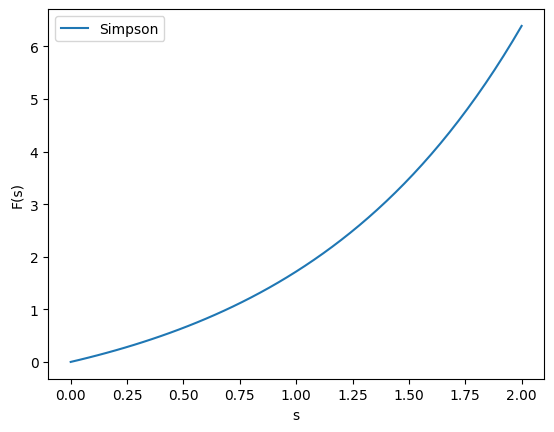

In [4]:
def f(t):
    return np.exp(t)
a,final=0.,2.
M,N=50,100
assert N>0 and N%2==0
valores_s=np.linspace(a,final,M+1)
F=np.zeros(M+1)
for j in range(M+1):
    s=valores_s[j]
    h=(s-a)/N
    t=a+np.arange(0,N,2)*h
    F[j]=h/3*np.sum(f(t)+4*f(t+h)+f(t+2*h))
print('Error máximo:',np.max(np.abs(F-(np.exp(valores_s)-1))))
assert np.allclose(F,np.exp(valores_s)-1)
plt.plot(valores_s,F,label='Simpson'); plt.xlabel('s'); plt.ylabel('F(s)'); plt.legend(); plt.show()

## 4. Integral doble — límites constantes o variables

Primero integrar en y con x fijo. Guardar cada resultado G[j]. Después integrar G en x. Ejemplo genérico triangular; para un rectángulo cambia c y d a constantes. Nx y Ny no tienen que ser iguales.

In [5]:
def f(x,y):
    return x+y

a,b=0.,1.
Nx,Ny=40,20
assert Nx>0 and Ny>0 and Nx%2==0 and Ny%2==0
hx=(b-a)/Nx
valores_x=np.linspace(a,b,Nx+1)
G=np.zeros(Nx+1)
for j in range(Nx+1):
    x=valores_x[j]
    c,d=0.,x # límites interiores: modificar según región
    hy=(d-c)/Ny
    y=c+np.arange(0,Ny,2)*hy
    G[j]=hy/3*np.sum(f(x,y)+4*f(x,y+hy)+f(x,y+2*hy))
suma=0.
for i in range(0,Nx,2):
    suma += G[i]+4*G[i+1]+G[i+2]
I=hx/3*suma
print(I)
assert np.isclose(I,.5)

0.5


## 5. Integrando una función compleja

NumPy conserva los complejos al sumar. Si guardas resultados en un arreglo, usa dtype=complex. Extrae real o imaginaria solo cuando el problema lo indique.

In [6]:
def f(t):
    return np.exp(1j*t)
a,b,N=0.,np.pi,100
assert N>0 and N%2==0
h=(b-a)/N
t=a+np.arange(0,N,2)*h
I=h/3*np.sum(f(t)+4*f(t+h)+f(t+2*h))
print(I)
assert np.allclose(I,2j,atol=1e-7)

(-2.139226012111961e-16+2.0000000108245044j)


## 6. Refinar y estimar error

Si el integrando es suficientemente suave y domina el error O(h⁴), |I(2N)−I(N)|/15 estima el error de I(2N). No es garantía; comprobar otro refinamiento.

In [7]:
def f(x):
    return 1/x
a,b=1.,2.
Ns=[10,20,40,80]
resultados=np.zeros(len(Ns))
for j in range(len(Ns)):
    N=Ns[j]
    h=(b-a)/N
    x=a+np.arange(0,N,2)*h
    resultados[j]=h/3*np.sum(f(x)+4*f(x+h)+f(x+2*h))
for j in range(1,len(Ns)):
    print(Ns[j],resultados[j], 'Error estimado:',abs(resultados[j]-resultados[j-1])/15)

20 0.6931473746651161 Error estimado: 1.9040158761492638e-07
40 0.693147192747956 Error estimado: 1.2127810674241364e-08
80 0.6931471813225869 Error estimado: 7.616912730175803e-10


Material de estudio adaptado del notebook de clases y de la versión FC2_C2. Ejemplos de práctica; no son soluciones de las tareas. Comprueba las reglas de uso de material asistido por IA.